# Transfer learning com YOLO

Aula 4 - Transfer Learning.

1. Ideia: reusar pesos pré-treinados (COCO)
2. Carregar `yolo11n`
3. Fine-tune em um domínio **diferente**: medical-pills
4. Ver ground truth do val e inferir em outra imagem

# 0. Instalando

In [65]:
# %pip install -q ultralytics torch pillow matplotlib

## 1. Imports

In [66]:
from pathlib import Path

%matplotlib inline

import torch
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO
from ultralytics.utils import SETTINGS

HERE = Path.cwd()
if HERE.name != "transfer_learning":
    HERE = Path("exemplos-aula-04/transfer_learning")

RUNS = HERE / "runs"
RUNS.mkdir(parents=True, exist_ok=True)

DATA_ROOT = Path(SETTINGS["datasets_dir"]) / "medical-pills"
device = 0 if torch.cuda.is_available() else "cpu"
print("Device:", device)
print("Pasta:", HERE)
print("Dataset:", DATA_ROOT)

Device: 0
Pasta: /home/thyago/luxai/deep-learning-pratica/exemplos-aula-04/transfer_learning
Dataset: /home/thyago/dtlabs/test/datasets/medical-pills


## 2. O que é transfer aqui?

Partimos de um detector treinado no **COCO** (cenas do dia a dia, 80 classes) e adaptamos a um domínio novo: **comprimidos** (`medical-pills`).

O ponto didático: não fine-tunar de volta no mesmo COCO - mudamos a tarefa/domínio, reusando a representação visual.

In [67]:
print("pretrained COCO → fine-tune em medical-pills (domínio novo)")
print("benefício: converge mais rápido do que treinar do zero com poucos dados")

pretrained COCO → fine-tune em medical-pills (domínio novo)
benefício: converge mais rápido do que treinar do zero com poucos dados


## 3. Carregar o modelo pré-treinado

`yolo11n.pt` = YOLO11 nano. Na primeira vez a lib baixa os pesos.

In [68]:
model = YOLO("yolo11n.pt")

print("Task:", model.task)
print("Classes (n):", len(model.names))
print("Algumas classes:", list(model.names.values())[:8], "...")

Task: detect
Classes (n): 80
Algumas classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck'] ...


## 4. Olhada rápida na arquitetura

In [69]:
n_layers, n_params, n_grads, flops = model.info()
print(f"layers={n_layers}  params={n_params}  grads={n_grads}  GFLOPs={flops}")

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.6 GFLOPs
layers=181  params=2624080  grads=0  GFLOPs=6.614336


## 5. Dataset: medical-pills

Dataset pequeno do Ultralytics (~8 MB): fotos de comprimidos, **1 classe** (`pill`).

- train: ~92 imagens
- val: ~23 imagens

Domínio bem diferente do COCO. `data="medical-pills.yaml"` baixa sozinho na primeira vez.

In [70]:
from ultralytics.data.utils import check_det_dataset

DATA = "medical-pills.yaml"
data_info = check_det_dataset(DATA)  # baixa se ainda não existir
print(DATA)
print("path:", data_info.get("path", DATA_ROOT))
print("classes novas: só 'pill' (a cabeça do detector é trocada no fine-tune)")


medical-pills.yaml
path: /home/thyago/dtlabs/test/datasets/medical-pills
classes novas: só 'pill' (a cabeça do detector é trocada no fine-tune)


## 6. Ground truth no val (10 imagens)

Antes do treino: 10 imagens do **val** com as boxes anotadas (YOLO: `class xc yc w h` normalizado).


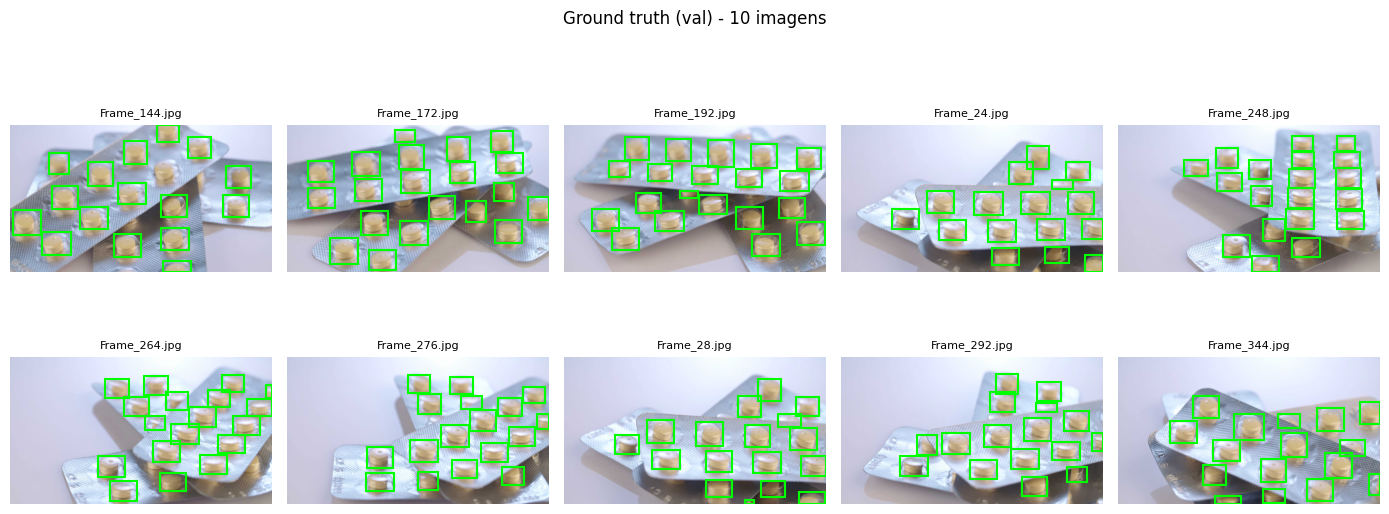

inferência vai usar: Frame_360.jpg


In [71]:
val_img_dir = DATA_ROOT / "images" / "val"
val_lbl_dir = DATA_ROOT / "labels" / "val"
val_images = sorted(val_img_dir.glob("*.jpg")) + sorted(val_img_dir.glob("*.png"))
if len(val_images) < 11:
    raise FileNotFoundError(
        f"Preciso de pelo menos 11 imagens em {val_img_dir}. "
        "Rode a célula do dataset (check_det_dataset) antes."
    )

gt_images = val_images[:10]
infer_image = val_images[10]  # outra imagem, fora das 10 do GT

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, img_path in zip(axes.ravel(), gt_images):
    im = Image.open(img_path).convert("RGB")
    w, h = im.size
    ax.imshow(im)

    label_path = val_lbl_dir / f"{img_path.stem}.txt"
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            cls_id, xc, yc, bw, bh = map(float, line.split())
            x0 = (xc - bw / 2) * w
            y0 = (yc - bh / 2) * h
            ax.add_patch(
                Rectangle(
                    (x0, y0),
                    bw * w,
                    bh * h,
                    fill=False,
                    linewidth=1.5,
                    edgecolor="lime",
                )
            )

    ax.set_title(img_path.name, fontsize=8)
    ax.axis("off")

fig.suptitle("Ground truth (val) - 10 imagens", fontsize=12)
plt.tight_layout()
plt.show()

print("inferência vai usar:", infer_image.name)


## 7. Fine-tune (transfer)

`pretrained=True` (default ao carregar `.pt`): partimos dos pesos COCO.
Poucas epochs - só para ver o domínio novo sendo aprendido.


In [72]:
train_results = model.train(
    data=DATA,
    epochs=20,
    batch=8,
    imgsz=640,
    device=device,
    workers=2,
    pretrained=True,
    project=str(RUNS),
    name="yolo_transfer_pills",
    exist_ok=True,
    verbose=True,
)
train_results

New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.192 🚀 Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 5773MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=medical-pills.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolo_transfer_pills, nbs=64, nms=False, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x763a573043d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## 8. Validação rápida

mAP no val de medical-pills. Dataset pequeno → número oscila; o foco é o **fluxo** de transfer.


In [73]:
metrics = model.val()
print(metrics)

Ultralytics 8.3.192 🚀 Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 5773MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1098.7±522.9 MB/s, size: 71.7 KB)
val: Scanning /home/thyago/dtlabs/test/datasets/medical-pills/labels/val.cache... 23 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 23/23 31372.0it/s 0.0s.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 4.8it/s 0.6s0.4s
                   all         23        399      0.975      0.992      0.993      0.783
Speed: 2.2ms preprocess, 9.6ms inference, 0.0ms loss, 6.2ms postprocess per image
Results saved to /home/thyago/luxai/deep-learning-pratica/exemplos-aula-04/transfer_learning/runs/yolo_transfer_pills
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_

## 9. Inferência em outra imagem

Mesmo split (val), mas **outra** foto - não entrou no grid do ground truth.
Depois da inferência, plotamos a imagem com a predição (boxes + conf).


Imagem: /home/thyago/dtlabs/test/datasets/medical-pills/images/val/Frame_360.jpg


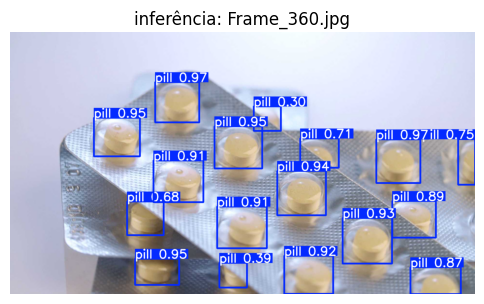

detecções: 17
  pill  conf=0.97
  pill  conf=0.97
  pill  conf=0.95
  pill  conf=0.95
  pill  conf=0.95
  pill  conf=0.94
  pill  conf=0.93
  pill  conf=0.92
  pill  conf=0.91
  pill  conf=0.91
  pill  conf=0.89
  pill  conf=0.87
  pill  conf=0.75
  pill  conf=0.71
  pill  conf=0.68
  pill  conf=0.39
  pill  conf=0.30


In [74]:
print("Imagem:", infer_image)

results = model.predict(
    source=str(infer_image),
    imgsz=640,
    conf=0.25,
    device=device,
    verbose=False,
)
result = results[0]
annotated = result.plot()[:, :, ::-1]

plt.figure(figsize=(6, 6))
plt.imshow(annotated)
plt.axis("off")
plt.title(f"inferência: {infer_image.name}")
plt.show()

print("detecções:", len(result.boxes))
for box in result.boxes:
    cls_id = int(box.cls.item())
    conf = float(box.conf.item())
    print(f"  {model.names[cls_id]}  conf={conf:.2f}")

## 10. Recap

1. Pesos COCO = ponto de partida forte  
2. Fine-tune adapta a um **domínio novo** (aqui: comprimidos)  
3. Com poucos exemplos, transfer costuma ganhar de treino do zero  

Na aula 3 você já viu dataset YOLO, NMS e export - aqui o foco foi só o **reuso de pesos**.


In [75]:
best = RUNS / "yolo_transfer_pills" / "weights" / "best.pt"
print("checkpoint:", best if best.exists() else "(veja runs/*/weights/best.pt)")

checkpoint: /home/thyago/luxai/deep-learning-pratica/exemplos-aula-04/transfer_learning/runs/yolo_transfer_pills/weights/best.pt


## 11. Liberar VRAM


In [76]:
import gc

for name in ["model", "results", "train_results", "metrics"]:
    globals().pop(name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free, total = torch.cuda.mem_get_info()
    print(f"VRAM livre: {free / 1e9:.2f} / {total / 1e9:.2f} GB")
else:
    print("CPU only")

VRAM livre: 4.13 / 6.05 GB
